# DSC 411/511 Project
# Notebook 11: RQ9 (new): Depth-Damage: How Does the Damage Ratio Depend on Water Depth, and Are Standard Curves Right?

**Class topics:** Lecture 03 (noise, placeholder codes, unit errors, binning), Lecture 07 (regression, evaluation,
cross-validation, leakage), Lecture 05 (tree models), plus regression extensions for a **ratio between 0 and 1**:
**beta regression**, **fractional logit**, the **Gamma GLM**, and **quantile bands**.

---

**How this question was derived.** Notebook 04 showed that storm and rain data help rank large losses, but the strongest
driver of damage, the **water depth inside the building**, is an adjuster field that we could not use as a feature
(it is measured after the flood). Engineers use depth all the time, through **depth-damage curves**: one curve gives the
damage (as a share of the building value) for each foot of water. Wing, Pinter, Bates & Kousky (2020, *Nature
Communications*) tested these curves with more than 2 million NFIP claims from 1972-2014. Their main findings:
- median relative damage rises with depth (at 1 ft: median 11%, middle half 4-30%; at 5 ft: middle half 19-90%), but the
  spread is huge;
- at every depth the damage ratio is **bimodal** (many claims near 0% and a surprising number near 100%) and is better
  described by a **beta distribution** than by one central value;
- a standard federal curve predicted individual claims **worse than the plain mean** (negative coefficient of
  determination);
- the depth field has **artefacts**: some depths look recorded in inches instead of feet, with heaps at 12 and 24.

> **RQ9. In 2020-2025 NFIP claims, how does the building damage ratio (damage / building value) depend on water depth
> (and flood duration)? Do we see the bimodal pattern of Wing et al. (2020)? How well does a standard USACE curve predict
> single claims compared with beta regression, fractional logit, a Gamma GLM and LightGBM? And are elevated buildings
> associated with lower damage at the same depth?**

**Framing.** Depth and damage are both measured by the adjuster after the flood, so this is an **engineering /
descriptive** model ("given the water depth, what damage?"), as depth-damage curves are. It is not a claim-time
prediction model.

---
# Section 0: Setup

In [1]:
import sys
import json
import time
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
import statsmodels.formula.api as smf
from statsmodels.othermod.betareg import BetaModel
from scipy import stats
import lightgbm as lgb
from sklearn.model_selection import GroupKFold
from sklearn.metrics import mean_absolute_error

sys.path.append('/Users/home/workspace/School/DataMining/nfip_claims')
from nfip_project_utils import *

warnings.filterwarnings('ignore')
sns.set_style('whitegrid')
pd.set_option('display.width', 200)
notebook_start = time.time()

claims = load_clean_claims()
# floodWaterDuration is not in the cleaned file; it comes from the merged file of notebook 00 (same claim id).
duration = pd.read_parquet(PROCESSED_DIR / 'claims_merged_2020_2025.parquet', columns=['id', 'floodWaterDuration'])
claims = claims.merge(duration.drop_duplicates('id'), on='id', how='left')
print(f'Cleaned claims 2020-2025: {len(claims):,}')

Cleaned claims 2020-2025: 253,124


---
# Section 1: Data Used and Excluded, and the Building-Value Leak

| Column | Role | Note |
|---|---|---|
| `buildingDamageAmount` | damage (actual cash value) | adjuster |
| `buildingPropertyValue` | building value before the flood (actual cash value) | adjuster; denominator of the ratio |
| `waterDepth` | water depth | data dictionary: "in inches. Note: there are instances where measurements were provided in feet" |
| `interiorWaterDepth` | interior water marks, inches | used to check the unit of `waterDepth` |
| `floodWaterDuration` | hours water stayed in the building | checked in Section 2.5 |
| `floors_group`, `basement_group`, `foundation_group` | building type | to match Wing et al. (one story, no basement) and the USACE curves |
| `elevatedBuildingIndicator`, `building_age_at_loss`, `postFIRMConstructionIndicator`, `in_special_flood_hazard_area` | building facts | |
| rain, storm wind, coast distance | flood type | |

**Damage ratio** = `buildingDamageAmount / buildingPropertyValue`, clipped to 0-1 (Wing et al. used the same ratio).

**The building-value leak.** Notebook 01 found that some adjuster fields are blank mostly on **unpaid** claims. We check
`buildingPropertyValue` the same way. If it is blank much more often for unpaid claims, then every analysis of the damage
ratio silently keeps mostly **paid** claims: a selected sample.

In [2]:
claims['building_value_missing'] = claims['buildingPropertyValue'].isna() | (claims['buildingPropertyValue'] <= 0)
leak_table = claims.groupby('building_paid_flag').agg(claims=('id', 'size'), building_value_missing_pct=('building_value_missing', 'mean'),
                                                      damage_missing_pct=('buildingDamageAmount', lambda s: s.isna().mean()))
leak_table[['building_value_missing_pct', 'damage_missing_pct']] *= 100
leak_table.index = leak_table.index.map({0: 'not paid', 1: 'paid'})
leak_table.round(2).to_csv(TABLE_DIR / '11_rq9_building_value_leak.csv')
print(leak_table.round(2).to_string())

                    claims  building_value_missing_pct  damage_missing_pct
building_paid_flag                                                        
not paid             42424                       57.15               40.20
paid                210700                        6.35                0.45


**How to read this.** `buildingPropertyValue` is missing on 57.2% of unpaid claims but only on 6.4% of paid claims. The damage amount is missing on 40.2% of unpaid claims and on 0.45% of paid claims.

So these fields are mostly filled in **after** an adjuster has inspected the claim and found damage. This has two consequences:

1. The building value must never be used as a feature to predict payment, because its presence alone gives the answer away (notebook 03 showed this leak).
2. The damage ratio (damage / value) exists almost only for paid claims, so every result in this notebook is about **claims with assessed damage**, not about all flooded homes.

---
# Section 2: Cleaning the Water Depth (step by step)

Wing et al. (2020) describe the problem: depths "should be in units of feet, but instead, in some cases, seem to be
recorded in inches", with "anomalous numbers of claims ... with depths of 12 and 24 feet". The OpenFEMA dictionary says
the opposite default (inches, sometimes feet). So we let the data decide, using `interiorWaterDepth`, which is documented
in inches. Notebook 13 (anomalies) uses the same checks as rule flags.

## 2.1 Placeholder codes
Notebook 01 already turned 999 and above into missing. We look for other heaps that are not measurements.

In [3]:
depth_counts = claims['waterDepth'].value_counts().sort_index()
print('Number of claims at selected waterDepth values:')
print(depth_counts.reindex([6, 7, 8, 9, 10, 11, 12, 13, 23, 24, 25, 35, 36, 37, 97, 98, 99, 100, 101]).fillna(0).astype(int).to_string())

Number of claims at selected waterDepth values:
waterDepth
6       2451
7       1688
8       1478
9        915
10       957
11       455
12       592
13       353
23       172
24       210
25       121
35        73
36       124
37        78
97         3
98         4
99     10864
100        5
101        3


**How to read this.** The counts fall smoothly from 6 to 13 and stay small after that. The exceptions are a small bump at 12, 24 and 36 (Section 2.3) and **10,864 claims at exactly 99**, while 98 and 100 have only 4 and 5. A depth of 99 ft is not a real flood depth, so 99 is a placeholder code (like 999) and we set it to missing.

## 2.2 Feet or inches? Compare with the interior water marks
For claims with both values above 0:
- **feet-like:** `waterDepth` x 12 is within 6 inches of `interiorWaterDepth` (the depth was written in feet, rounded);
- **inch-like:** `waterDepth` is within 1 inch of `interiorWaterDepth` (written in inches), for values of 2 or more;
- **inconsistent:** neither.

In [4]:
both = claims[(claims['waterDepth'] > 0) & (claims['interiorWaterDepth'] > 0) & (claims['waterDepth'] != 99)].copy()
both['unit_check'] = np.select([np.abs(both['waterDepth'] * 12 - both['interiorWaterDepth']) <= 6,
                                (np.abs(both['waterDepth'] - both['interiorWaterDepth']) <= 1) & (both['waterDepth'] >= 2)],
                               ['feet-like', 'inch-like'], 'inconsistent')
unit_table = both.groupby('loss_year')['unit_check'].value_counts(normalize=True).unstack().mul(100).round(1)
unit_table['claims'] = both.groupby('loss_year').size()
unit_table.to_csv(TABLE_DIR / '11_rq9_depth_unit_check.csv')
print(f'Claims with both depths > 0: {len(both):,}')
print(both['unit_check'].value_counts(normalize=True).mul(100).round(1).to_string())
print('\nBy loss year (%):'); print(unit_table.to_string())

Claims with both depths > 0: 66,827
unit_check
feet-like       80.3
inch-like       17.3
inconsistent     2.4

By loss year (%):
unit_check  feet-like  inch-like  inconsistent  claims
loss_year                                             
2020             90.0        7.1           2.9    5092
2021             89.9        6.4           3.7    7812
2022             77.1       21.0           1.9   16065
2023             82.6       14.8           2.6    4667
2024             76.9       20.9           2.2   31071
2025             90.3        7.4           2.3    2120


**How to read this.** 66,827 claims have both depths above 0. Of these, 80.3% look like **feet**, 17.3% look like inches, and 2.4% are inconsistent.

So, contrary to the data dictionary, `waterDepth` is mostly in feet, as Wing et al. (2020) assumed. The inch-like share changes from year to year: about 7% in 2020, 2021 and 2025, but 21% in 2022 and 2024, the years of Ian and Helene. This suggests that recording habits differ between storms or adjuster firms. A fixed "divide by 12" rule would therefore be wrong for most claims.

## 2.3 Heaping at multiples of 12
If a depth of 12 or 24 is really "12 or 24 inches" written in the feet field, those values will stand out compared with
their neighbours (11 and 13, 23 and 25).

In [5]:
heap_rows = []
for value in [12, 24, 36]:
    neighbours = (depth_counts.get(value - 1, 0) + depth_counts.get(value + 1, 0)) / 2
    heap_rows.append({'depth_value': value, 'claims': int(depth_counts.get(value, 0)), 'mean_of_neighbours': neighbours,
                      'heap_ratio': depth_counts.get(value, 0) / neighbours if neighbours else np.nan,
                      'inch_like_share_%': (both.loc[both['waterDepth'] == value, 'unit_check'] == 'inch-like').mean() * 100})
heap_table = pd.DataFrame(heap_rows).round(2)
heap_table.to_csv(TABLE_DIR / '11_rq9_depth_heaping.csv', index=False)
print(heap_table.to_string(index=False))

 depth_value  claims  mean_of_neighbours  heap_ratio  inch_like_share_%
          12     592               404.0        1.47              85.96
          24     210               146.5        1.43              98.09
          36     124                75.5        1.64             100.00


## 2.4 The cleaning rule
1. `waterDepth` = 99 is a placeholder -> missing.
2. If `interiorWaterDepth` is available and above 0: feet-like -> keep the value as feet; inch-like -> divide by 12;
   inconsistent -> missing.
3. If there is no interior value: keep the value as feet only if it is between -2 and 8 (Wing et al. kept depths below
   8 ft "where records in feet seem to dominate"); otherwise missing. This removes the 12/24 heaps without a check.
4. Keep depths from -2 to 16 ft (the range of the USACE tables).

In [6]:
def clean_depth_feet(data):
    raw = data['waterDepth'].where(data['waterDepth'] != 99)
    interior = data['interiorWaterDepth']
    has_interior = (interior > 0) & (raw > 0)
    feet_like = has_interior & (np.abs(raw * 12 - interior) <= 6)
    inch_like = has_interior & ~feet_like & (np.abs(raw - interior) <= 1) & (raw >= 2)
    depth = pd.Series(np.nan, index=data.index)
    depth[feet_like] = raw[feet_like]
    depth[inch_like] = raw[inch_like] / 12
    no_check = ~has_interior & raw.between(-2, 8)
    depth[no_check] = raw[no_check]
    return depth.where(depth.between(-2, 16))


claims['depth_feet'] = clean_depth_feet(claims)
claims['damage_ratio'] = (claims['buildingDamageAmount'] / claims['buildingPropertyValue'].where(claims['buildingPropertyValue'] > 0)).clip(0, 1)
cleaning_summary = pd.Series({'claims with any waterDepth': int(claims['waterDepth'].notna().sum()),
                              'placeholder 99': int((claims['waterDepth'] == 99).sum()),
                              'clean depth (feet) available': int(claims['depth_feet'].notna().sum()),
                              'clean depth + damage > 0 + building value > 0': int((claims['depth_feet'].notna() & (claims['buildingDamageAmount'] > 0) & claims['damage_ratio'].notna()).sum())})
print(cleaning_summary.to_string())

claims with any waterDepth                       218858
placeholder 99                                    10864
clean depth (feet) available                     195602
clean depth + damage > 0 + building value > 0    163294


## 2.5 Flood duration
Wing et al. did not use duration; USACE (EGM 01-03) reports that duration added little once depth was known. We check
whether the field can be used at all.

In [7]:
duration_known = claims['floodWaterDuration'].notna()
duration_summary = pd.Series({'claims': len(claims), 'duration filled %': duration_known.mean() * 100,
                              'duration > 0 hours, % of all claims': (claims['floodWaterDuration'] > 0).mean() * 100,
                              'median hours where > 0': claims.loc[claims['floodWaterDuration'] > 0, 'floodWaterDuration'].median()}).round(2)
duration_summary.to_csv(TABLE_DIR / '11_rq9_duration_field.csv')
print(duration_summary.to_string())

claims                                 253124.00
duration filled %                           5.68
duration > 0 hours, % of all claims         0.97
median hours where > 0                      1.00


**How to read this (Sections 2.3-2.5).**

- **Heaping.** The values 12, 24 and 36 have 1.4-1.6 times as many claims as their neighbours. 86-100% of them are inch-like when an interior depth exists, so they are mostly "1, 2 or 3 feet written in inches".
- **After cleaning.** 195,602 claims have a usable depth in feet. 163,294 of them also have damage > 0 and a building value.
- **Duration.** `floodWaterDuration` is filled for only 5.7% of claims and is above 0 for 1.0%, with a median of 1 hour. The field cannot be used, so the analysis is **depth only**, as in Wing et al. and USACE.

---
# Section 3: Reproducing Wing et al. (2020): One-Story Homes Without a Basement, 1-8 ft

Wing et al. focused on single-family, **one-story, no-basement** homes (51% of their claims), depths of 1 to 8 ft. We
use the same filter: `occupancy_group` = single family, `floors_group` = one floor, no basement (basement field "none" or
a slab, crawlspace or elevated foundation), damage > 0, building value > 0, clean depth rounded to whole feet.

In [8]:
residential = claims[claims['occupancy_group'].isin(['single_family', 'multi_family_2to4']) & (claims['buildingDamageAmount'] > 0)
                     & claims['damage_ratio'].notna() & claims['depth_feet'].notna()].copy()
residential['has_basement'] = (residential['basement_group'].isin(['finished_basement', 'unfinished_basement'])
                               | (residential['foundation_group'] == 'basement')).astype(int)
residential['no_basement_known'] = (residential['has_basement'] == 0) & (residential['basement_group'].isin(['none', 'subgrade_crawlspace'])
                                                                         | residential['foundation_group'].isin(['slab', 'crawlspace', 'elevated_enclosed_piles', 'elevated_enclosed_walls', 'elevated_open_piles']))
residential['depth_whole_feet'] = residential['depth_feet'].round()
wing_sample = residential[(residential['occupancy_group'] == 'single_family') & (residential['floors_group'] == 'one_floor')
                          & residential['no_basement_known'] & residential['depth_whole_feet'].between(1, 8)].copy()
print(f'Residential claims with clean depth and damage ratio: {len(residential):,}; Wing-style sample: {len(wing_sample):,}')

BIN_EDGES = np.linspace(0, 1, 11)
wing_rows, histogram_rows = [], []
for depth, group in wing_sample.groupby('depth_whole_feet'):
    ratio = group['damage_ratio']
    squeezed = ratio.clip(0.001, 0.999)
    alpha_hat, beta_hat, _, _ = stats.beta.fit(squeezed, floc=0, fscale=1)
    shares = np.histogram(ratio, bins=BIN_EDGES)[0] / len(ratio) * 100
    histogram_rows.append(pd.Series(shares, index=[f'{int(a * 100)}-{int(b * 100)}%' for a, b in zip(BIN_EDGES[:-1], BIN_EDGES[1:])], name=int(depth)))
    wing_rows.append({'depth_ft': int(depth), 'claims': len(group), 'Q25': ratio.quantile(0.25), 'median': ratio.median(), 'Q75': ratio.quantile(0.75),
                      'share_0_10%': shares[0], 'share_90_100%': shares[-1], 'beta_alpha': alpha_hat, 'beta_beta': beta_hat,
                      'U_shaped_beta (alpha<1 and beta<1)': (alpha_hat < 1) and (beta_hat < 1)})
wing_table = pd.DataFrame(wing_rows).round(3)
histogram_table = pd.DataFrame(histogram_rows).round(1)
wing_table.to_csv(TABLE_DIR / '11_rq9_wing_reproduction.csv', index=False)
histogram_table.to_csv(TABLE_DIR / '11_rq9_damage_ratio_histograms.csv')
print(wing_table.to_string(index=False))
print('\nShare of claims (%) in each 10% damage bin, by depth (rows):')
print(histogram_table.to_string())

Residential claims with clean depth and damage ratio: 136,510; Wing-style sample: 47,531


 depth_ft  claims   Q25  median   Q75  share_0_10%  share_90_100%  beta_alpha  beta_beta  U_shaped_beta (alpha<1 and beta<1)
        1   25075 0.173   0.386 0.527       18.449          2.241       0.975      1.590                               False
        2   11431 0.301   0.458 0.597       13.796          3.840       1.053      1.309                               False
        3    5900 0.331   0.490 0.640       12.763          4.831       1.073      1.187                               False
        4    3063 0.334   0.514 0.689       11.851          6.301       1.057      1.058                               False
        5     963 0.283   0.542 0.763       14.330         12.461       0.845      0.747                                True
        6     504 0.185   0.557 0.788       18.254         13.095       0.726      0.664                                True
        7     335 0.226   0.661 0.858       14.030         19.701       0.727      0.559                                True


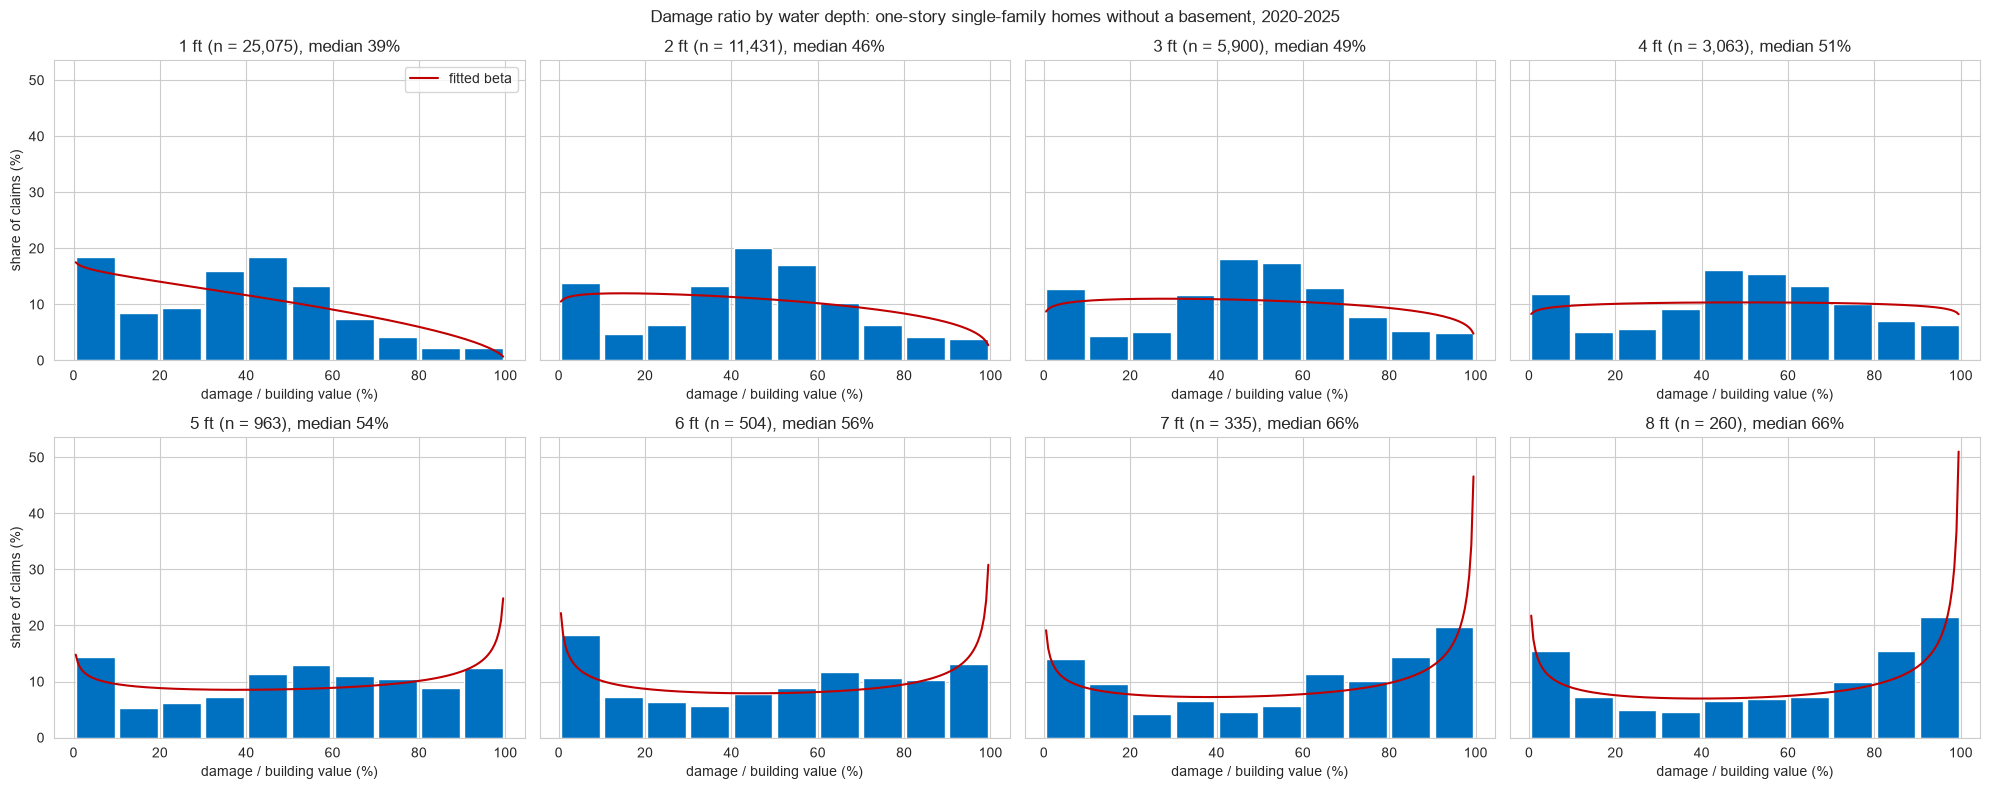

In [9]:
fig, axes = plt.subplots(2, 4, figsize=(20, 8), sharey=True)
for ax, (depth, shares) in zip(axes.ravel(), histogram_table.iterrows()):
    ax.bar(np.arange(10) * 10 + 5, shares.values, width=9, color='#0070C0')
    row = wing_table[wing_table['depth_ft'] == depth].iloc[0]
    grid = np.linspace(0.005, 0.995, 200)
    ax.plot(grid * 100, stats.beta.pdf(grid, row['beta_alpha'], row['beta_beta']) * 10, color='#C00000', label='fitted beta')
    ax.set_title(f'{depth} ft (n = {int(row["claims"]):,}), median {row["median"] * 100:.0f}%')
    ax.set_xlabel('damage / building value (%)')
axes[0, 0].set_ylabel('share of claims (%)'); axes[1, 0].set_ylabel('share of claims (%)'); axes[0, 0].legend()
plt.suptitle('Damage ratio by water depth: one-story single-family homes without a basement, 2020-2025')
plt.tight_layout(); plt.savefig(FIGURE_DIR / '11_rq9_bimodal_by_depth.png', dpi=120); plt.show()

**How to read this.** We reproduce the main finding of Wing et al. (2020): the damage ratio at a given depth is **very spread out and often bimodal**.

- At 1 ft the middle half of claims runs from 17% to 53% damage (median 39%). At 5 ft it runs from 28% to 76% (median 54%).
- The 0-10% bin holds 12-18% of claims at **every** depth, including 15% at 8 ft. At the same time, the 90-100% bin grows from 2.2% at 1 ft to 21.5% at 8 ft.
- The fitted beta distribution is bell-shaped or flat at 1-4 ft (alpha and beta near 1). It becomes **U-shaped** (alpha < 1 and beta < 1) at 5-8 ft: 4 of 8 depths. So deeper floods split homes into "almost no damage" and "almost total loss", as Wing et al. found.
- The median still rises with depth, but slowly (0.39 -> 0.66 from 1 to 8 ft). Depth alone explains little of the damage.

---
# Section 4: The Standard Curve: USACE Generic Depth-Damage Functions

The U.S. Army Corps of Engineers published generic residential curves in **EGM 01-03** (4 Dec 2000; homes without a
basement) and **EGM 04-01** (10 Oct 2003; homes with a basement). Each table gives the **mean structure damage as a
percentage of the structure value** for each foot of depth relative to the first floor. The values below are copied from
the tables in those memoranda. For a claim we pick the table by floors and basement and interpolate linearly between feet.

In [10]:
USACE_DEPTHS = np.arange(-2, 17)
USACE_CURVES = {   # % damage at depths -2, -1, 0, 1, ..., 16 ft
    'one story, no basement (EGM 01-03 Table 1)': [0, 2.5, 13.4, 23.3, 32.1, 40.1, 47.1, 53.2, 58.6, 63.2, 67.2, 70.5, 73.2, 75.4, 77.2, 78.5, 79.5, 80.2, 80.7],
    'two+ stories, no basement (EGM 01-03 Table 2)': [0, 3.0, 9.3, 15.2, 20.9, 26.3, 31.4, 36.2, 40.7, 44.9, 48.8, 52.4, 55.7, 58.7, 61.4, 63.8, 65.9, 67.7, 69.2],
    'one story, with basement (EGM 04-01 Table 1)': [13.8, 19.4, 25.5, 32.0, 38.7, 45.5, 52.2, 58.6, 64.5, 69.8, 74.2, 77.7, 80.1, 81.1, 81.1, 81.1, 81.1, 81.1, 81.1],
    'two+ stories, with basement (EGM 04-01 Table 2)': [10.2, 13.9, 17.9, 22.3, 27.0, 31.9, 36.9, 41.9, 46.9, 51.8, 56.4, 60.8, 64.8, 68.4, 71.4, 73.7, 75.4, 76.4, 76.4],
}
print(pd.DataFrame(USACE_CURVES, index=USACE_DEPTHS).T.to_string())


def usace_prediction(data):
    one_story = data['floors_group'].isin(['one_floor', 'manufactured_home', 'split_level'])
    basement = data['has_basement'] == 1
    names = np.select([one_story & ~basement, ~one_story & ~basement, one_story & basement],
                      list(USACE_CURVES)[:3], list(USACE_CURVES)[3])
    prediction = np.empty(len(data))
    for name in USACE_CURVES:
        rows = names == name
        prediction[rows] = np.interp(data['depth_feet'].values[rows], USACE_DEPTHS, USACE_CURVES[name]) / 100
    return prediction


def coefficient_of_determination(y, prediction):
    """Wing et al. (2020), Eq. 1: 1 - residual variance / data variance. Below 0 means worse than the mean."""
    return 1 - np.sum((y - prediction) ** 2) / np.sum((y - np.mean(y)) ** 2)


wing_sample['usace'] = usace_prediction(wing_sample)
usace_rows = []
for depth, group in wing_sample.groupby('depth_whole_feet'):
    usace_rows.append({'depth_ft': int(depth), 'observed_mean': group['damage_ratio'].mean(), 'observed_median': group['damage_ratio'].median(),
                       'USACE_curve': group['usace'].mean(), 'mean_error (curve - observed)': (group['usace'] - group['damage_ratio']).mean(),
                       'CoD': coefficient_of_determination(group['damage_ratio'].values, group['usace'].values),
                       'MAE_as_%_of_mean_damage': mean_absolute_error(group['damage_ratio'], group['usace']) / group['damage_ratio'].mean() * 100})
usace_table = pd.DataFrame(usace_rows).round(3)
usace_table.to_csv(TABLE_DIR / '11_rq9_usace_vs_observed.csv', index=False)
print(usace_table.to_string(index=False))
print(f"\nAll depths 1-8 ft: CoD of the USACE curve = {coefficient_of_determination(wing_sample['damage_ratio'].values, wing_sample['usace'].values):.3f}")

                                                  -2    -1     0     1     2     3     4     5     6     7     8     9     10    11    12    13    14    15    16
one story, no basement (EGM 01-03 Table 1)        0.0   2.5  13.4  23.3  32.1  40.1  47.1  53.2  58.6  63.2  67.2  70.5  73.2  75.4  77.2  78.5  79.5  80.2  80.7
two+ stories, no basement (EGM 01-03 Table 2)     0.0   3.0   9.3  15.2  20.9  26.3  31.4  36.2  40.7  44.9  48.8  52.4  55.7  58.7  61.4  63.8  65.9  67.7  69.2
one story, with basement (EGM 04-01 Table 1)     13.8  19.4  25.5  32.0  38.7  45.5  52.2  58.6  64.5  69.8  74.2  77.7  80.1  81.1  81.1  81.1  81.1  81.1  81.1
two+ stories, with basement (EGM 04-01 Table 2)  10.2  13.9  17.9  22.3  27.0  31.9  36.9  41.9  46.9  51.8  56.4  60.8  64.8  68.4  71.4  73.7  75.4  76.4  76.4
 depth_ft  observed_mean  observed_median  USACE_curve  mean_error (curve - observed)    CoD  MAE_as_%_of_mean_damage
        1          0.375            0.386        0.233                  

**How to read this.** The USACE curve (one story, no basement) **under-predicts shallow floods**: at 1 ft it gives 0.23, but the observed mean is 0.38 (error -0.14). It **over-predicts deep floods**: at 8 ft it gives 0.67 against 0.58 observed (error +0.10).

Its coefficient of determination on the Wing-style sample is **-0.20**, worse than simply using the overall mean (CoD = 0). Wing et al. reported the same kind of poor fit (their Eq. 1).

Part of the gap may come from the reference level: USACE depth is measured above the first floor, while the NFIP field's reference (ground or floor) is not fully documented.

---
# Section 5: Four Models for a Ratio Between 0 and 1 (step by step)

We now use **all residential claims** with a clean depth (single-family and 2-4 family, any number of floors, with or
without basement), train on 2020-2023 and test on 2024-2025. Every model gets the same inputs: a smooth curve of depth
(a natural cubic spline with 4 degrees of freedom), floors, basement, elevated building, building age, post-FIRM, inside
the SFHA, zone V, log building value, coast distance, storm wind and 3-day rain.

**5.1 Fractional logit (Papke & Wooldridge 1996).** The ratio $y \in [0, 1]$ is treated like a probability:
$E[y \mid x] = 1 / (1 + e^{-x^\top\beta})$. We fit it with the Bernoulli likelihood (a GLM with binomial family). The
estimate of the **mean** is correct even though $y$ is not 0/1 ("quasi-likelihood").

**5.2 Beta regression (Ferrari & Cribari-Neto 2004).** We assume $y$ follows a **beta distribution**, the shape Wing et
al. found. A beta has a mean $\mu$ and a precision $\phi$; its density can be U-shaped (bimodal), flat or bell-shaped.
Step by step: (1) $\text{logit}(\mu_i) = x_i^\top\beta$; (2) $y_i \sim \text{Beta}(\mu_i\phi, (1-\mu_i)\phi)$; (3) maximise the
log-likelihood over $\beta$ and $\phi$. A beta cannot take exactly 0 or 1, so we squeeze: $y' = (y(n-1) + 0.5)/n$
(Smithson & Verkuilen 2006). For speed, the beta model is fitted on a 40,000-claim random sample of the training rows.

**5.3 Gamma GLM.** For a positive, right-skewed outcome: $\log E[y] = x^\top\beta$ and variance $\propto$ mean$^2$. It does
not know that $y \le 1$, so predictions above 1 are clipped.

**5.4 LightGBM with a cross-entropy objective.** Gradient-boosted trees that minimise the same Bernoulli loss as the
fractional logit, but can learn thresholds and interactions.

**Baselines:** the **USACE curve** (Section 4) and the **training mean** (one number for everyone).

In [11]:
FORMULA_TERMS = ('cr(depth_feet, df=4, constraints="center") + C(floors_simple) + has_basement + elevatedBuildingIndicator + building_age'
                 ' + postFIRMConstructionIndicator + in_special_flood_hazard_area + zone_V + log_building_value'
                 ' + log_coast_distance + storm_wind + rain_3day')
residential['floors_simple'] = residential['floors_group'].replace({'split_level': 'two_floors', 'townhouse_3plus': 'three_plus_floors'})
residential['zone_V'] = (residential['flood_zone_group'] == 'V_coastal_high_hazard').astype(int)
residential['building_age'] = residential['building_age_at_loss'].fillna(residential['building_age_at_loss'].median())
residential['log_building_value'] = np.log(residential['buildingPropertyValue'])
residential['log_coast_distance'] = np.log1p(residential['coast_distance_km'].fillna(residential['coast_distance_km'].median()))
residential['storm_wind'] = residential['storm_wind_at_closest_kt'].fillna(0)
residential['rain_3day'] = residential['rain_3day_mm'].fillna(residential['rain_3day_mm'].median())
n_rows = len(residential)
residential['damage_ratio_squeezed'] = (residential['damage_ratio'] * (n_rows - 1) + 0.5) / n_rows
residential['damage_ratio_positive'] = residential['damage_ratio'].clip(lower=1e-4)
residential['usace'] = usace_prediction(residential)
TREE_FEATURES = ['depth_feet', 'has_basement', 'elevatedBuildingIndicator', 'building_age', 'postFIRMConstructionIndicator',
                 'in_special_flood_hazard_area', 'zone_V', 'log_building_value', 'log_coast_distance', 'storm_wind', 'rain_3day']
residential = residential.reset_index(drop=True)
train_rows = residential[residential['loss_year'].isin(TRAIN_YEARS)].reset_index(drop=True)
test_rows = residential[residential['loss_year'].isin(TEST_YEARS)].reset_index(drop=True)
BETA_SAMPLE = 40_000
print(f'Residential claims: train {len(train_rows):,} ({train_rows["event_group"].nunique()} events), test {len(test_rows):,} ({test_rows["event_group"].nunique()} events)')


def fit_predict(model_name, fit_rows, score_rows):
    if model_name == 'training mean':
        return np.full(len(score_rows), fit_rows['damage_ratio'].mean())
    if model_name == 'USACE curve':
        return score_rows['usace'].values
    if model_name == 'fractional logit':
        result = smf.glm(f'damage_ratio ~ {FORMULA_TERMS}', data=fit_rows, family=sm.families.Binomial()).fit()
        return result.predict(score_rows).values
    if model_name == 'Gamma GLM':
        result = smf.glm(f'damage_ratio_positive ~ {FORMULA_TERMS}', data=fit_rows, family=sm.families.Gamma(link=sm.families.links.Log())).fit()
        return np.clip(result.predict(score_rows).values, 0, 1)
    if model_name == 'beta regression':
        sample = fit_rows.sample(min(BETA_SAMPLE, len(fit_rows)), random_state=SEED)
        result = BetaModel.from_formula(f'damage_ratio_squeezed ~ {FORMULA_TERMS}', data=sample).fit(disp=0, maxiter=500)
        return np.asarray(result.predict(score_rows))
    model = lgb.LGBMRegressor(objective='cross_entropy', n_estimators=500, learning_rate=0.05, num_leaves=31, min_child_samples=100,
                              subsample=0.8, subsample_freq=1, colsample_bytree=0.8, random_state=SEED, verbose=-1)
    frame = fit_rows[TREE_FEATURES].assign(floors=fit_rows['floors_simple'].astype('category'))
    model.fit(frame, fit_rows['damage_ratio'])
    score_frame = score_rows[TREE_FEATURES].assign(floors=pd.Categorical(score_rows['floors_simple'], categories=frame['floors'].cat.categories))
    return model.predict(score_frame)


MODEL_NAMES = ['training mean', 'USACE curve', 'fractional logit', 'beta regression', 'Gamma GLM', 'LightGBM (cross-entropy)']

Residential claims: train 76,436 (44 events), test 60,074 (26 events)


In [12]:
start = time.time()
cv_rows = []
for fold, (fit_index, validation_index) in enumerate(GroupKFold(n_splits=5).split(train_rows, groups=train_rows['event_group'])):
    fit_rows, validation_rows = train_rows.iloc[fit_index], train_rows.iloc[validation_index]
    for model_name in MODEL_NAMES:
        prediction = fit_predict(model_name, fit_rows, validation_rows)
        cv_rows.append({'model': model_name, 'fold': fold, 'MAE': mean_absolute_error(validation_rows['damage_ratio'], prediction),
                        'CoD': coefficient_of_determination(validation_rows['damage_ratio'].values, prediction)})
cv_table = pd.DataFrame(cv_rows).groupby('model')[['MAE', 'CoD']].agg(['mean', 'std']).round(4).reindex(MODEL_NAMES)
cv_table.to_csv(TABLE_DIR / '11_rq9_event_grouped_cv.csv')
print(f'Event-grouped 5-fold CV on 2020-2023 ({time.time() - start:.0f} s):')
print(cv_table.to_string())

Event-grouped 5-fold CV on 2020-2023 (24 s):
                             MAE             CoD        
                            mean     std    mean     std
model                                                   
training mean             0.2070  0.0226 -0.0739  0.0631
USACE curve               0.1875  0.0290 -0.0365  0.0448
fractional logit          0.1579  0.0161  0.2484  0.0562
beta regression           0.1723  0.0111  0.1851  0.0811
Gamma GLM                 0.1586  0.0142  0.2353  0.0610
LightGBM (cross-entropy)  0.1523  0.0173  0.2521  0.0496


In [13]:
for model_name in MODEL_NAMES:
    test_rows[f'pred_{model_name}'] = fit_predict(model_name, train_rows, test_rows)
metric_functions = {'MAE': mean_absolute_error, 'CoD': coefficient_of_determination,
                    'RMSE': lambda y, p: np.sqrt(np.mean((y - p) ** 2))}
test_table = event_block_bootstrap(test_rows, 'damage_ratio', {name: f'pred_{name}' for name in MODEL_NAMES}, metric_functions,
                                   baseline='USACE curve', n_repeats=500).round(4)
test_table = test_table.rename(columns={'gain_vs_baseline': 'difference_vs_USACE'})
test_table.to_csv(TABLE_DIR / '11_rq9_test_years_models.csv', index=False)
print('Test years 2024-2025 (MAE/RMSE: lower is better; CoD: higher is better). Differences are model - USACE curve:')
print(test_table.drop(columns=['events', 'valid_repeats']).to_string(index=False))

Test years 2024-2025 (MAE/RMSE: lower is better; CoD: higher is better). Differences are model - USACE curve:
metric                    model   value  difference_vs_USACE  ci_95_low  ci_95_high  share_of_repeats_with_gain_%
   MAE            training mean  0.2235               0.0120     0.0020      0.0250                          99.8
   MAE              USACE curve  0.2116                  NaN        NaN         NaN                           NaN
   MAE         fractional logit  0.1654              -0.0462    -0.0620     -0.0086                           0.2
   MAE          beta regression  0.1694              -0.0422    -0.0607      0.0013                           3.4
   MAE                Gamma GLM  0.1683              -0.0433    -0.0577     -0.0080                           0.2
   MAE LightGBM (cross-entropy)  0.1535              -0.0580    -0.0747     -0.0181                           0.0
   CoD            training mean -0.0844              -0.0089    -0.0549      0.1126         

**How to read this.** All four models beat the USACE curve and the training mean, both in CV and on the new storms of 2024-2025.

- **CV (2020-2023, 5 event folds):** the MAE is 0.152 +/- 0.017 for LightGBM, 0.158 +/- 0.016 for the fractional logit, 0.159 +/- 0.014 for the Gamma GLM and 0.172 +/- 0.011 for the beta regression. USACE has 0.188 +/- 0.029 and the training mean 0.207.
- **Test years:** LightGBM has MAE 0.154, which is 0.058 [0.018, 0.075] below USACE (0.212), and CoD 0.37 against -0.08 for USACE. The fractional logit (-0.046 [-0.062, -0.009]) and the Gamma GLM (-0.043 [-0.058, -0.008]) also beat USACE. For the beta regression the MAE CI just touches 0 (+0.001), but its RMSE and CoD gains are significant.
- The three GLMs are close to each other. LightGBM is best, but only by about 0.01 MAE over the fractional logit. A test CoD of 0.37 means that most of the claim-to-claim spread stays unexplained.
- The beta regression is fitted on a 40,000-claim sample (it is slow), which may explain its slightly worse MAE.

---
# Section 6: Quantile Bands P10 / P50 / P90

Because the spread is the main message, we also predict three **quantiles** of the damage ratio with LightGBM
(`objective='quantile'`, the pinball loss of Section 5.3 in notebook 10). If the bands are honest, about 80% of test
claims fall between P10 and P90.

In [14]:
band_predictions = {}
for quantile in [0.1, 0.5, 0.9]:
    model = lgb.LGBMRegressor(objective='quantile', alpha=quantile, n_estimators=400, learning_rate=0.05, num_leaves=31,
                              min_child_samples=100, subsample=0.8, subsample_freq=1, colsample_bytree=0.8, random_state=SEED, verbose=-1)
    model.fit(train_rows[TREE_FEATURES].assign(floors=train_rows['floors_simple'].astype('category')), train_rows['damage_ratio'])
    band_predictions[quantile] = np.clip(model.predict(test_rows[TREE_FEATURES].assign(
        floors=pd.Categorical(test_rows['floors_simple'], categories=sorted(train_rows['floors_simple'].unique())))), 0, 1)
test_rows['P10'], test_rows['P50'], test_rows['P90'] = band_predictions[0.1], band_predictions[0.5], band_predictions[0.9]
test_rows['inside_band'] = (test_rows['damage_ratio'] >= test_rows['P10']) & (test_rows['damage_ratio'] <= test_rows['P90'])
test_rows['depth_bin'] = pd.cut(test_rows['depth_feet'], [-2.01, 0, 1, 2, 3, 4, 6, 8, 16])
band_table = test_rows.groupby('depth_bin', observed=True).agg(claims=('id', 'size'), observed_P10=('damage_ratio', lambda s: s.quantile(0.1)),
                                                               observed_median=('damage_ratio', 'median'), observed_P90=('damage_ratio', lambda s: s.quantile(0.9)),
                                                               predicted_P10=('P10', 'mean'), predicted_P50=('P50', 'mean'), predicted_P90=('P90', 'mean'),
                                                               share_inside_P10_P90=('inside_band', 'mean'), USACE_curve=('usace', 'mean')).round(3)
band_table.to_csv(TABLE_DIR / '11_rq9_quantile_bands.csv')
print(f"Share of all test claims inside [P10, P90]: {test_rows['inside_band'].mean():.3f} (target 0.80); mean band width {(test_rows['P90'] - test_rows['P10']).mean():.3f}")
print(band_table.to_string())

Share of all test claims inside [P10, P90]: 0.724 (target 0.80); mean band width 0.415
              claims  observed_P10  observed_median  observed_P90  predicted_P10  predicted_P50  predicted_P90  share_inside_P10_P90  USACE_curve
depth_bin                                                                                                                                        
(-2.01, 0.0]   19338         0.017            0.184         0.591          0.046          0.198          0.426                 0.720        0.129
(0.0, 1.0]     17966         0.034            0.366         0.662          0.102          0.296          0.526                 0.723        0.216
(1.0, 2.0]     11185         0.025            0.412         0.725          0.156          0.329          0.552                 0.713        0.292
(2.0, 3.0]      6472         0.028            0.436         0.759          0.184          0.361          0.626                 0.746        0.365
(3.0, 4.0]      3328         0.041   

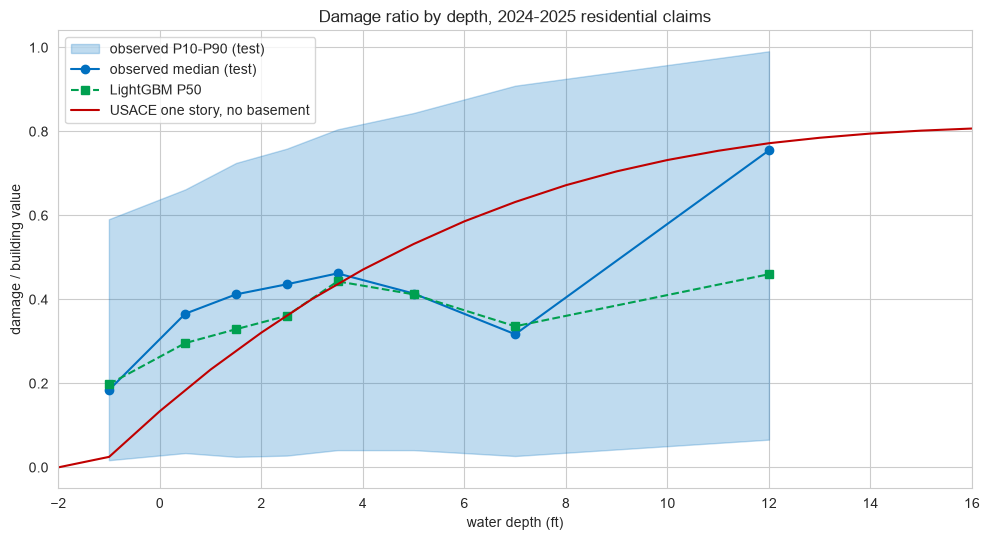

In [15]:
fig, ax = plt.subplots(figsize=(10, 5.5))
centres = [interval.mid for interval in band_table.index]
ax.fill_between(centres, band_table['observed_P10'], band_table['observed_P90'], alpha=0.25, color='#0070C0', label='observed P10-P90 (test)')
ax.plot(centres, band_table['observed_median'], 'o-', color='#0070C0', label='observed median (test)')
ax.plot(centres, band_table['predicted_P50'], 's--', color='#00A050', label='LightGBM P50')
ax.plot(USACE_DEPTHS, np.array(USACE_CURVES['one story, no basement (EGM 01-03 Table 1)']) / 100, color='#C00000', label='USACE one story, no basement')
ax.set_xlabel('water depth (ft)'); ax.set_ylabel('damage / building value'); ax.set_xlim(-2, 16); ax.legend()
ax.set_title('Damage ratio by depth, 2024-2025 residential claims')
plt.tight_layout(); plt.savefig(FIGURE_DIR / '11_rq9_quantile_bands.png', dpi=120); plt.show()

**How to read this.** The LightGBM P10-P90 band contains **72.4%** of the test claims, not the 80% it should. The band is too narrow.

- The predicted P10 (0.05-0.21) sits well above the observed P10 (0.02-0.07), because the models cannot predict the heap of near-zero claims.
- At 6-16 ft only 54-60% of claims fall inside the band, because the U-shaped spread at depth is wider than the model learned.

For planning, use the bands as a rough range only. A real loss can be far outside them, mainly for deep floods.

---
# Section 7: Elevated Buildings: Lower Damage at the Same Depth? (association, not cause)

We compare elevated and non-elevated homes **within the same depth**, and read the elevated coefficient of the beta
regression fitted on all residential claims (40,000-claim sample), which also holds the other building and flood facts
constant. $e^{\beta}$ is the change in the **odds of the mean damage ratio** $\mu / (1 - \mu)$.

Caution: this is an association. Elevated homes differ in many ways (newer, coastal, built to code), and the depth
field's reference level (ground or floor) is not fully documented, so part of the difference may be measurement.

In [16]:
elevation_rows = []
for depth, group in residential[residential['depth_whole_feet'].between(0, 8)].groupby('depth_whole_feet'):
    for elevated, part in group.groupby('elevatedBuildingIndicator'):
        elevation_rows.append({'depth_ft': int(depth), 'elevated': int(elevated), 'claims': len(part),
                               'median_ratio': part['damage_ratio'].median(), 'share_above_90%': (part['damage_ratio'] > 0.9).mean() * 100})
elevation_table = pd.DataFrame(elevation_rows).pivot(index='depth_ft', columns='elevated', values=['claims', 'median_ratio', 'share_above_90%']).round(3)
elevation_table.to_csv(TABLE_DIR / '11_rq9_elevated_by_depth.csv')
print(elevation_table.to_string())

beta_sample = residential.sample(BETA_SAMPLE, random_state=SEED)
beta_all = BetaModel.from_formula(f'damage_ratio_squeezed ~ {FORMULA_TERMS}', data=beta_sample).fit(disp=0, maxiter=500)
elevated_low, elevated_high = beta_all.conf_int().loc['elevatedBuildingIndicator']
elevated_odds = (np.exp(beta_all.params['elevatedBuildingIndicator']), np.exp(elevated_low), np.exp(elevated_high), beta_all.pvalues['elevatedBuildingIndicator'])
precision_phi = np.exp(beta_all.params['precision']) if 'precision' in beta_all.params else np.nan
print(f'\nBeta regression (all residential, n = {BETA_SAMPLE:,}): elevated odds ratio of mean damage = {elevated_odds[0]:.3f} '
      f'[{elevated_odds[1]:.3f}-{elevated_odds[2]:.3f}], p = {elevated_odds[3]:.4f}; precision phi = {precision_phi:.2f}')
pd.DataFrame({'coef': beta_all.params, 'p_value': beta_all.pvalues}).round(4).to_csv(TABLE_DIR / '11_rq9_beta_regression_coefficients.csv')

           claims         median_ratio        share_above_90%        
elevated        0       1            0      1               0       1
depth_ft                                                             
0         42014.0  8215.0        0.178  0.055           1.411   2.386
1         37757.0  5478.0        0.341  0.084           1.759   2.227
2         16567.0  3334.0        0.413  0.064           2.946   2.879
3          8284.0  1981.0        0.446  0.054           4.116   3.130
4          4275.0  1178.0        0.479  0.079           5.895   5.518
5          1433.0   801.0        0.485  0.092           9.351   8.614
6           764.0   541.0        0.475  0.081          10.733   5.545
7           513.0   340.0        0.499  0.110          13.840   8.529
8           392.0   274.0        0.567  0.140          18.878  11.314



Beta regression (all residential, n = 40,000): elevated odds ratio of mean damage = 0.623 [0.604-0.642], p = 0.0000; precision phi = 2.70


**How to read this (association, not cause).** At every depth, elevated homes have a much lower median damage ratio. At 1 ft it is 0.08 against 0.34, and at 4 ft 0.08 against 0.48. However, their share of near-total losses (> 90%) is similar or lower.

In the beta regression, which also holds depth, floors, basement, age, zone, value, coast distance, wind and rain constant, being elevated goes with **0.62 times the odds of the mean damage ratio** [95% CI 0.60-0.64].

This is a strong association, but it is not proof of a causal effect. Elevated homes are newer, more often built to code and coastal. Also, if their `waterDepth` is measured from the ground rather than from the raised floor, part of the gap is a measurement effect.

---
# Section 8: Leakage and Selection

- **Not a claim-time model.** Depth, damage and building value are all written by the adjuster after the flood.
  Depth-damage curves are always used this way: once a depth is known (measured or modelled), they give the damage. So
  using depth here is the point of the analysis, not a leak. None of these models may be used to predict payments at
  the time a claim is filed.
- **Building value is blank mostly on unpaid claims** (Section 1). The damage ratio exists almost only for adjusted,
  paid claims, so the curves describe **paid** claims. Low-damage claims that ended below the deductible are under-
  represented, so the true share of near-zero ratios is probably even larger.
- **The depth field is noisy.** We removed placeholders, fixed units with the interior water marks, and dropped
  unverified large values. Some unit errors certainly remain.
- **Duration** is blank or zero for almost all claims, so it could not be tested.

---
## The numbers behind the answer

In [17]:
def test_value(model, metric, column='value'):
    return test_table[(test_table['model'] == model) & (test_table['metric'] == metric)].iloc[0][column]


def test_difference_text(model, metric):
    row = test_table[(test_table['model'] == model) & (test_table['metric'] == metric)].iloc[0]
    return f"{row['value']:.4f} (vs USACE {row['difference_vs_USACE']:+.4f} [{row['ci_95_low']:+.4f}, {row['ci_95_high']:+.4f}])"


one_foot = wing_table[wing_table['depth_ft'] == 1].iloc[0]
five_feet = wing_table[wing_table['depth_ft'] == 5].iloc[0]
eight_feet = wing_table[wing_table['depth_ft'] == 8].iloc[0]
rows = [
    ('building value missing: not paid vs paid (%)', f"{leak_table.loc['not paid', 'building_value_missing_pct']:.1f} vs {leak_table.loc['paid', 'building_value_missing_pct']:.1f}", '11_rq9_building_value_leak'),
    ('depth unit check: feet-like / inch-like / inconsistent (%)', ' / '.join(f"{both['unit_check'].value_counts(normalize=True).get(k, 0) * 100:.1f}" for k in ['feet-like', 'inch-like', 'inconsistent']), '11_rq9_depth_unit_check'),
    ('waterDepth = 99 placeholder claims', int((claims['waterDepth'] == 99).sum()), 'Section 2.1'),
    ('heap ratio at 12 / 24 (count vs neighbours)', f"{heap_table.loc[0, 'heap_ratio']:.2f} / {heap_table.loc[1, 'heap_ratio']:.2f}", '11_rq9_depth_heaping'),
    ('flood duration filled (%) / > 0 (%)', f"{duration_summary['duration filled %']:.1f} / {duration_summary['duration > 0 hours, % of all claims']:.1f}", '11_rq9_duration_field'),
    ('Wing-style sample (one-story, no basement, 1-8 ft)', len(wing_sample), '11_rq9_wing_reproduction'),
    ('1 ft: median (Q25-Q75)', f"{one_foot['median']:.2f} ({one_foot['Q25']:.2f}-{one_foot['Q75']:.2f})", '11_rq9_wing_reproduction'),
    ('5 ft: median (Q25-Q75)', f"{five_feet['median']:.2f} ({five_feet['Q25']:.2f}-{five_feet['Q75']:.2f})", '11_rq9_wing_reproduction'),
    ('1 ft / 8 ft: share in 0-10% bin', f"{one_foot['share_0_10%']:.1f}% / {eight_feet['share_0_10%']:.1f}%", '11_rq9_wing_reproduction'),
    ('1 ft / 8 ft: share in 90-100% bin', f"{one_foot['share_90_100%']:.1f}% / {eight_feet['share_90_100%']:.1f}%", '11_rq9_wing_reproduction'),
    ('depths with U-shaped beta fit (alpha<1, beta<1)', f"{int(wing_table['U_shaped_beta (alpha<1 and beta<1)'].sum())} of {len(wing_table)}", '11_rq9_wing_reproduction'),
    ('USACE curve CoD, 1-8 ft Wing sample', coefficient_of_determination(wing_sample['damage_ratio'].values, wing_sample['usace'].values), '11_rq9_usace_vs_observed'),
    ('USACE mean error at 1 ft / 8 ft (curve - observed)', f"{usace_table.iloc[0]['mean_error (curve - observed)']:+.3f} / {usace_table.iloc[-1]['mean_error (curve - observed)']:+.3f}", '11_rq9_usace_vs_observed'),
]
for model_name in MODEL_NAMES:
    rows.append((f'CV MAE {model_name} (mean +/- SD)', f"{cv_table.loc[model_name, ('MAE', 'mean')]:.4f} +/- {cv_table.loc[model_name, ('MAE', 'std')]:.4f}", '11_rq9_event_grouped_cv'))
for model_name in MODEL_NAMES:
    if model_name != 'USACE curve':
        rows.append((f'test MAE {model_name} (difference vs USACE [95% CI])', test_difference_text(model_name, 'MAE'), '11_rq9_test_years_models'))
rows += [
    ('test MAE USACE curve', test_value('USACE curve', 'MAE'), '11_rq9_test_years_models'),
    ('test CoD: USACE / best model (LightGBM)', f"{test_value('USACE curve', 'CoD'):.3f} / {test_value('LightGBM (cross-entropy)', 'CoD'):.3f}", '11_rq9_test_years_models'),
    ('test share inside LightGBM P10-P90 (target 0.80)', test_rows['inside_band'].mean(), '11_rq9_quantile_bands'),
    ('beta regression: elevated odds ratio of mean damage [95% CI]', f"{elevated_odds[0]:.3f} [{elevated_odds[1]:.3f}-{elevated_odds[2]:.3f}], p = {elevated_odds[3]:.4f}", '11_rq9_beta_regression_coefficients'),
]
answer_numbers = show_answer_numbers(rows, '11_rq9')
print(f'\nNotebook run time: {(time.time() - notebook_start) / 60:.1f} min')

                                                        quantity                                        value                              source
                    building value missing: not paid vs paid (%)                                  57.2 vs 6.4          11_rq9_building_value_leak
      depth unit check: feet-like / inch-like / inconsistent (%)                            80.3 / 17.3 / 2.4             11_rq9_depth_unit_check
                              waterDepth = 99 placeholder claims                                        10864                         Section 2.1
                     heap ratio at 12 / 24 (count vs neighbours)                                  1.47 / 1.43                11_rq9_depth_heaping
                             flood duration filled (%) / > 0 (%)                                    5.7 / 1.0               11_rq9_duration_field
              Wing-style sample (one-story, no basement, 1-8 ft)                                        47531            11_

---
# Research Question -> Answer

**Research question (RQ9):** How does the NFIP damage ratio (building damage / building value) depend on water depth and flood duration? Do the claims reproduce Wing et al.'s (2020) wide, bimodal pattern? How do the standard USACE curve and four learned models compare on new storms?

**Answer (from the numbers above).**

1. **The depth field needs cleaning first.** 10,864 claims carry a 99 placeholder. Against the interior water marks, 80% of depths are in feet and 17% in inches (21% in 2022 and 2024). The 12/24/36 heaps are mostly inches. After cleaning, 195,602 claims have a usable depth. **Duration cannot be used**: it is filled for 5.7% of claims and above 0 for 1.0%.
2. **Wing et al. reproduced.** For one-story homes without a basement (47,531 claims), the median damage rises only from 0.39 at 1 ft to 0.66 at 8 ft. 12-18% of claims sit below 10% damage at every depth, and the distribution becomes U-shaped from 5 ft (4 of 8 depths).
3. **The USACE curve fits badly.** CoD is -0.20 on the Wing sample and -0.08 on the 2024-2025 test claims. It is too low at shallow depths (-0.14 at 1 ft) and too high at deep ones (+0.10 at 8 ft).
4. **Learned models are better, but only moderately.** On the test years LightGBM has MAE 0.154 (USACE 0.212; difference -0.058 [-0.075, -0.018]) and CoD 0.37. The fractional logit, Gamma GLM and beta regression reach CoD 0.29-0.31. CV gives the same ranking (LightGBM 0.152 +/- 0.017).
5. **Bands are too narrow.** The P10-P90 band covers 72% of test claims instead of 80%, and only 54-60% beyond 6 ft.
6. **Elevated homes** have about 0.62 times the odds of the mean damage ratio [0.60-0.64] at the same depth and other facts. This is an association, not a measured causal effect.

**Bottom line:** depth matters, but the damage ratio at a given depth is so spread out (and bimodal at depth) that a single curve is a poor estimate for one home. Use predicted ranges, not a point value, and calibrate the curves on recent claims.

**References for this notebook.**
- Wing, O. E. J., Pinter, N., Bates, P. D. & Kousky, C. (2020). New insights into US flood vulnerability revealed from flood insurance big data. *Nature Communications* 11, 1444. https://doi.org/10.1038/s41467-020-15264-2
- U.S. Army Corps of Engineers (2000). *Economic Guidance Memorandum (EGM) 01-03, Generic Depth-Damage Relationships* (4 December 2000). https://planning.erdc.dren.mil/toolbox/library/EGMs/egm01-03.pdf
- U.S. Army Corps of Engineers (2003). *Economic Guidance Memorandum (EGM) 04-01, Generic Depth-Damage Relationships for Residential Structures with Basements* (10 October 2003). https://planning.erdc.dren.mil/toolbox/library/EGMs/egm04-01.pdf
- FEMA. *OpenFEMA Dataset: FIMA NFIP Redacted Claims - v3* (data dictionary: `waterDepth`, `interiorWaterDepth`, `floodWaterDuration`, `buildingPropertyValue`). https://www.fema.gov/openfema-data-page/nfip-redacted-claims-v3
- Ferrari, S. & Cribari-Neto, F. (2004). Beta regression for modelling rates and proportions. *Journal of Applied Statistics* 31(7), 799-815.
- Papke, L. E. & Wooldridge, J. M. (1996). Econometric methods for fractional response variables with an application to 401(k) plan participation rates. *Journal of Applied Econometrics* 11(6), 619-632.
- Smithson, M. & Verkuilen, J. (2006). A better lemon squeezer? Maximum-likelihood regression with beta-distributed dependent variables. *Psychological Methods* 11(1), 54-71.
- Ke, G. et al. (2017). LightGBM: A highly efficient gradient boosting decision tree. *Advances in Neural Information Processing Systems* 30.